# 6주차 MLP 실습 2 — MNIST 손글씨 분류 다층 퍼셉트론 (PyTorch)

**기계학습특론** · 성명: 최승호 · 이메일: jcn99250@naver.com

> 이전 버전(TensorFlow/Keras)을 **PyTorch 2.x** 기준으로 전면 개정한 노트북입니다. Colab에서는 `런타임 → 런타임 유형 변경 → GPU(T4)`를 선택하면 빠르게 실행됩니다 (CPU에서도 동작).

## [1] 실습 목표

실습 1(XOR)을 토대로, 더 복잡한 실제 데이터(MNIST: 훈련 60,000장 · 테스트 10,000장, 28×28 흑백 손글씨 숫자)로 **다중 클래스 분류** MLP를 구현·학습·평가한다.

1. `torchvision`으로 MNIST를 불러오고 `DataLoader`로 미니배치를 구성한다.
2. `nn.Module`을 상속해 **784 → 600 → 500 → 10** 구조의 MLP를 정의한다 (기존 Keras 모델과 동일 구조).
3. `nn.CrossEntropyLoss`(소프트맥스 + CCE 결합)와 `AdamW`, 학습률 스케줄러로 학습한다.
4. 정확도·혼동행렬·오분류 사례로 모델을 평가한다.
5. (심화) **활성화 함수 · 최적화기 · 정규화(BatchNorm/Dropout) · 초기화**가 성능에 미치는 영향을 비교 실험한다.
6. (참고) `torch.compile`, 혼합정밀도(AMP) 등 최신 학습 가속 기법을 소개한다.

## [2] 코드 구현의 흐름

1. (데이터) MNIST 불러오기 → 2. (데이터 확인) 특징 확인 → 3. (모델) MLP 구현 → 4. (학습) 학습 루프 → 5. (평가) 테스트 성능 · 혼동행렬 → 6. (실험) 구성 요소 비교


In [1]:
import os, time, random
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, random_split

print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

def set_seed(seed=1):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(1)

PyTorch 2.14.0+cu130 | torchvision 0.29.0+cu130
device: cpu


## 1) 데이터 불러오기

- **MNIST** (Modified National Institute of Standards and Technology): 0~9 손글씨 숫자 이미지 분류의 표준 벤치마크.
- `transforms.ToTensor()`는 0~255 정수 픽셀을 0~1 실수 텐서 `(1, 28, 28)`로 바꾼다.
- `transforms.Normalize(mean, std)`로 **표준화**하면 입력 분포가 0 근처에 모여 학습이 안정된다 (MNIST 전체 평균 0.1307, 표준편차 0.3081).

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),                        # [0,255] uint8 → [0,1] float, shape (1,28,28)
    transforms.Normalize((0.1307,), (0.3081,)),   # 표준화 (x - mean) / std
])
train_full = torchvision.datasets.MNIST(root="data", train=True,  download=True, transform=transform)
test_ds    = torchvision.datasets.MNIST(root="data", train=False, download=True, transform=transform)

# 훈련 데이터의 일부(10%)를 검증(validation) 데이터로 떼어 둔다 → 하이퍼파라미터 선택과 과적합 감시에 사용
train_ds, val_ds = random_split(train_full, [54000, 6000], generator=torch.Generator().manual_seed(1))
print(f"train {len(train_ds)} / val {len(val_ds)} / test {len(test_ds)}")

x0, y0 = train_full[0]
print("이미지 텐서 shape:", x0.shape, "| 레이블:", y0, "| 픽셀 값 범위:", (x0.min().item(), x0.max().item()))

train 54000 / val 6000 / test 10000
이미지 텐서 shape: torch.Size([1, 28, 28]) | 레이블: 5 | 픽셀 값 범위: (-0.4242129623889923, 2.821486711502075)


## 2) 데이터 특징 확인하기

클래스별 개수: {np.int64(0): np.int64(5923), np.int64(1): np.int64(6742), np.int64(2): np.int64(5958), np.int64(3): np.int64(6131), np.int64(4): np.int64(5842), np.int64(5): np.int64(5421), np.int64(6): np.int64(5918), np.int64(7): np.int64(6265), np.int64(8): np.int64(5851), np.int64(9): np.int64(5949)}


/tmp/ipykernel_2183/3454926939.py:1: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  labels = np.array(train_full.targets)


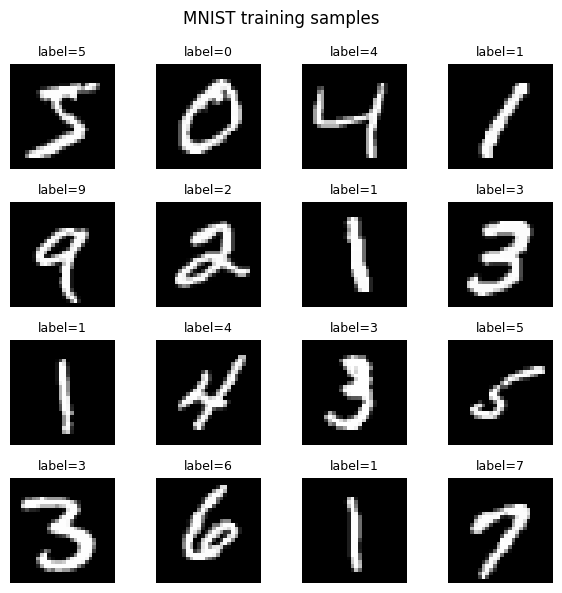

In [3]:
labels = np.array(train_full.targets)
print("클래스별 개수:", dict(zip(*np.unique(labels, return_counts=True))))

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for i, ax in enumerate(axes.flat):
    img, lab = train_full.data[i], train_full.targets[i].item()
    ax.imshow(img, cmap="gray"); ax.set_title(f"label={lab}", fontsize=9); ax.axis("off")
plt.suptitle("MNIST training samples"); plt.tight_layout(); plt.show()

### DataLoader: 미니배치 구성

- 전체 데이터(60,000장)를 한 번에 넣지 않고 **미니배치**(예: 128장)씩 나누어 경사를 계산한다 → 확률적 경사 하강법(mini-batch SGD).
- `shuffle=True`는 매 에폭마다 데이터 순서를 섞어 배치 구성이 고정되는 것을 막는다.

In [4]:
BATCH = 128
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=torch.cuda.is_available())
val_loader   = DataLoader(val_ds,   batch_size=1024,  shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=1024,  shuffle=False, num_workers=2)

xb, yb = next(iter(train_loader))
print("배치 입력 shape:", xb.shape, "| 배치 레이블 shape:", yb.shape)
print("1 에폭 = 미니배치", len(train_loader), "개")

배치 입력 shape: torch.Size([128, 1, 28, 28]) | 배치 레이블 shape: torch.Size([128])
1 에폭 = 미니배치 422 개


## 3) 모델 구현 — `nn.Module`

기존 Keras 모델 `Flatten → Dense(600, relu) → Dense(500, relu) → Dense(10, softmax)`을 PyTorch로 옮긴다.

> **주의:** PyTorch에서는 출력층에 `Softmax`를 두지 **않는다**. `nn.CrossEntropyLoss`가 내부에서 `log_softmax`와 음의 로그가능도를 수치적으로 안정하게 함께 계산하기 때문이다 (출력층은 **로짓 z**만 반환).

$$\hat{\mathbf{y}} = \mathrm{softmax}(\mathbf{z}), \qquad
\mathrm{CCE} = -\frac{1}{N}\sum_{i=1}^{N}\sum_{k=1}^{10} y_{ik}\ln \hat{y}_{ik}$$

In [5]:
class MLP(nn.Module):
    def __init__(self, in_dim=28*28, h1=600, h2=500, n_classes=10,
                 act=nn.ReLU, use_bn=False, dropout=0.0):
        super().__init__()
        layers = [nn.Flatten()]                       # (B,1,28,28) → (B,784)
        for din, dout in [(in_dim, h1), (h1, h2)]:
            layers.append(nn.Linear(din, dout))       # 가중합 z = Wx + b
            if use_bn: layers.append(nn.BatchNorm1d(dout))   # (선택) 배치 정규화
            layers.append(act())                      # 활성화 함수
            if dropout > 0: layers.append(nn.Dropout(dropout))  # (선택) 드롭아웃
        layers.append(nn.Linear(h2, n_classes))       # 출력층: 로짓 (softmax는 손실 함수 안에서)
        self.net = nn.Sequential(*layers)
        self._init_weights()

    def _init_weights(self):
        # He(Kaiming) 초기화: ReLU 계열 활성화 함수에서 각 층의 출력 분산을 일정하게 유지
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu"); nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.net(x)

model = MLP().to(device)
print(model)
n_params = sum(p.numel() for p in model.parameters())
print(f"학습 파라미터 수: {n_params:,}  (784·600+600 + 600·500+500 + 500·10+10)")

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=600, bias=True)
    (2): ReLU()
    (3): Linear(in_features=600, out_features=500, bias=True)
    (4): ReLU()
    (5): Linear(in_features=500, out_features=10, bias=True)
  )
)
학습 파라미터 수: 776,510  (784·600+600 + 600·500+500 + 500·10+10)


### 참고: 활성화 함수와 소프트맥스 직접 계산해 보기

In [6]:
scores = torch.tensor([3., -2., -1.3, 0., 1.8, 1.7])
print("ReLU   :", F.relu(scores).numpy().round(3))
print("GELU   :", F.gelu(scores).numpy().round(3))
print("softmax:", F.softmax(scores, dim=0).numpy().round(3), "| 합 =", F.softmax(scores, dim=0).sum().item())

ReLU   : [3.  0.  0.  0.  1.8 1.7]
GELU   : [ 2.996 -0.046 -0.126  0.     1.735  1.624]
softmax: [0.608 0.004 0.008 0.03  0.183 0.166] | 합 = 1.0


## 4) 학습 루프

- **손실 함수**: `nn.CrossEntropyLoss` — 정수 레이블(0~9)을 그대로 받는다 (Keras의 `sparse_categorical_crossentropy`에 해당).
- **최적화기**: `AdamW` — Adam에 **분리된 가중치 감쇠(decoupled weight decay)** 를 결합한, 현재 가장 널리 쓰이는 기본 선택.
- **학습률 스케줄러**: `OneCycleLR` — 학습률을 서서히 올렸다가(warm-up) 줄이는(annealing) 방식으로 짧은 학습에서도 높은 성능을 낸다.
- `model.train()` / `model.eval()`: Dropout·BatchNorm처럼 학습·추론 시 동작이 다른 층을 위해 반드시 전환한다.

In [7]:
def evaluate(model, loader):
    model.eval(); correct = total = 0; loss_sum = 0.0
    with torch.no_grad():                          # 평가 시에는 기울기 계산 불필요 → 메모리·시간 절약
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss_sum += F.cross_entropy(logits, yb, reduction="sum").item()
            correct += (logits.argmax(1) == yb).sum().item(); total += yb.size(0)
    return loss_sum / total, correct / total

def train(model, epochs=5, lr=2e-3, weight_decay=1e-2, verbose=True):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, epochs=epochs, steps_per_epoch=len(train_loader))
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); run_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                     # 1) 순전파
            loss = criterion(logits, yb)           # 2) 손실
            optimizer.zero_grad(set_to_none=True)  # 3) 기울기 초기화
            loss.backward()                        # 4) 역전파
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # (선택) 기울기 클리핑: 폭주 방지
            optimizer.step()                       # 5) 가중치 갱신
            scheduler.step()                       # 6) 학습률 갱신
            run_loss += loss.item() * yb.size(0)
        vl, va = evaluate(model, val_loader)
        history["train_loss"].append(run_loss / len(train_ds)); history["val_loss"].append(vl); history["val_acc"].append(va)
        if verbose:
            print(f"epoch {ep}/{epochs}  train_loss={history['train_loss'][-1]:.4f}  val_loss={vl:.4f}  val_acc={va:.4f}  ({time.time()-t0:.1f}s)")
    return history

set_seed(1)
model = MLP().to(device)
history = train(model, epochs=5)

epoch 1/5  train_loss=0.3610  val_loss=0.1729  val_acc=0.9487  (13.5s)


epoch 2/5  train_loss=0.1417  val_loss=0.1096  val_acc=0.9657  (13.1s)


epoch 3/5  train_loss=0.0693  val_loss=0.0909  val_acc=0.9728  (13.1s)


epoch 4/5  train_loss=0.0241  val_loss=0.0594  val_acc=0.9830  (13.2s)


epoch 5/5  train_loss=0.0072  val_loss=0.0569  val_acc=0.9828  (12.7s)


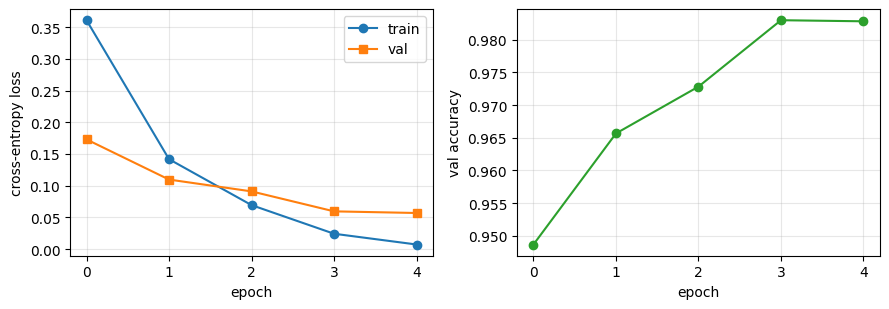

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(history["train_loss"], "o-", label="train"); ax[0].plot(history["val_loss"], "s-", label="val")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy loss"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(history["val_acc"], "o-", color="C2"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("val accuracy"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5) 테스트 데이터 평가 — 정확도 · 혼동행렬 · 오분류 사례

- **정확도(accuracy)**: 전체 중 맞춘 비율. 클래스 균형이 좋은 MNIST에서는 적절한 지표.
- **혼동행렬(confusion matrix)**: 행 = 실제 클래스, 열 = 예측 클래스. 어떤 숫자끼리 혼동되는지 보여 준다 (예: 4↔9, 3↔5, 7↔2).

테스트 손실 = 0.0552, 테스트 정확도 = 0.9852


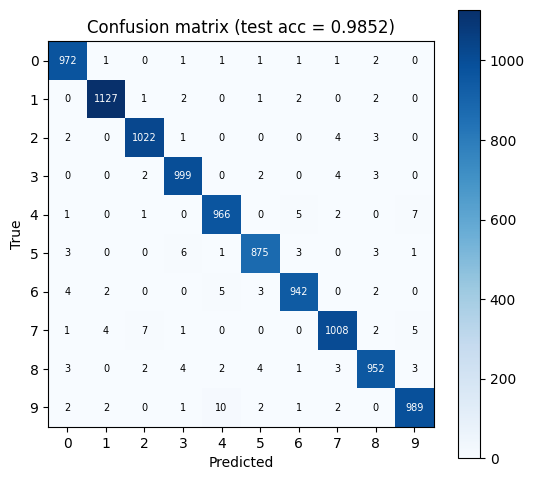

클래스별 정확도: {0: np.float64(0.992), 1: np.float64(0.993), 2: np.float64(0.99), 3: np.float64(0.989), 4: np.float64(0.984), 5: np.float64(0.981), 6: np.float64(0.983), 7: np.float64(0.981), 8: np.float64(0.977), 9: np.float64(0.98)}


In [9]:
test_loss, test_acc = evaluate(model, test_loader)
print(f"테스트 손실 = {test_loss:.4f}, 테스트 정확도 = {test_acc:.4f}")

# 예측값 수집
model.eval(); preds, trues = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        preds.append(model(xb.to(device)).argmax(1).cpu()); trues.append(yb)
preds, trues = torch.cat(preds).numpy(), torch.cat(trues).numpy()

cm = np.zeros((10, 10), dtype=int)
for t, p in zip(trues, preds): cm[t, p] += 1

plt.figure(figsize=(5.5, 5)); plt.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max()/2 else "black")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.xticks(range(10)); plt.yticks(range(10)); plt.title(f"Confusion matrix (test acc = {test_acc:.4f})")
plt.colorbar(); plt.tight_layout(); plt.show()

# 클래스별 정확도(재현율)
per_class = cm.diagonal() / cm.sum(1)
print("클래스별 정확도:", {k: round(v, 3) for k, v in enumerate(per_class)})

오분류 개수: 148 / 10000


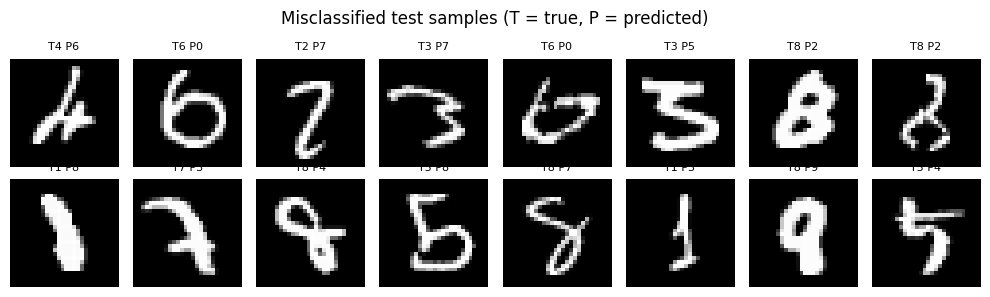

In [10]:
wrong = np.where(preds != trues)[0]
print(f"오분류 개수: {len(wrong)} / {len(trues)}")
fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for ax, idx in zip(axes.flat, wrong[:16]):
    ax.imshow(test_ds.data[idx], cmap="gray"); ax.set_title(f"T{trues[idx]} P{preds[idx]}", fontsize=8); ax.axis("off")
plt.suptitle("Misclassified test samples (T = true, P = predicted)"); plt.tight_layout(); plt.show()

## 6) (심화) 구성 요소 비교 실험

같은 784-600-500-10 구조에서 아래 요소를 바꿔 가며 **검증 정확도**를 비교한다 (각 3 에폭, 동일 시드).

| 실험 | 활성화 | 정규화 | 드롭아웃 | 최적화기 |
|---|---|---|---|---|
| A (baseline, 2010년대 초) | Sigmoid | – | – | SGD |
| B | ReLU | – | – | SGD + momentum |
| C | ReLU | – | – | AdamW + OneCycle |
| D | GELU | BatchNorm | 0.2 | AdamW + OneCycle |

> 실행 시간을 줄이려면 `EPOCHS`를 2로, 더 정밀하게 보려면 5로 바꿔 보세요.

A: Sigmoid + SGD                   val acc by epoch = [0.8827 0.9103 0.9107]
B: ReLU + SGD(momentum)            val acc by epoch = [0.9568 0.963  0.9697]
C: ReLU + AdamW + OneCycle         val acc by epoch = [0.9568 0.9723 0.9797]
D: GELU + BN + Dropout + AdamW     val acc by epoch = [0.963  0.973  0.9798]


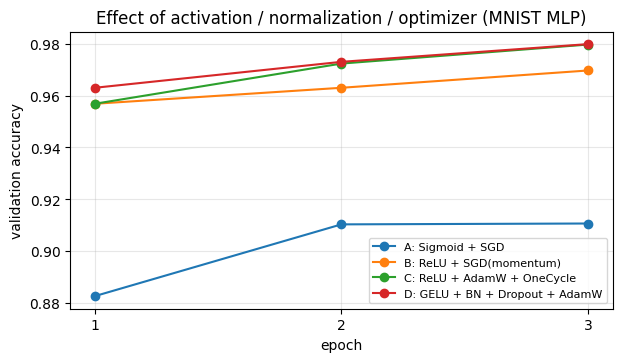

In [11]:
EPOCHS = 3

def train_generic(model, optimizer, scheduler=None, epochs=EPOCHS):
    crit = nn.CrossEntropyLoss(); accs = []
    for ep in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = crit(model(xb), yb); optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
            if scheduler: scheduler.step()
        accs.append(evaluate(model, val_loader)[1])
    return accs

experiments = {}
set_seed(1); m = MLP(act=nn.Sigmoid).to(device)
experiments["A: Sigmoid + SGD"] = train_generic(m, torch.optim.SGD(m.parameters(), lr=0.1))
set_seed(1); m = MLP(act=nn.ReLU).to(device)
experiments["B: ReLU + SGD(momentum)"] = train_generic(m, torch.optim.SGD(m.parameters(), lr=0.1, momentum=0.9))
set_seed(1); m = MLP(act=nn.ReLU).to(device); opt = torch.optim.AdamW(m.parameters(), lr=2e-3, weight_decay=1e-2)
experiments["C: ReLU + AdamW + OneCycle"] = train_generic(m, opt, torch.optim.lr_scheduler.OneCycleLR(opt, 2e-3, epochs=EPOCHS, steps_per_epoch=len(train_loader)))
set_seed(1); m = MLP(act=nn.GELU, use_bn=True, dropout=0.2).to(device); opt = torch.optim.AdamW(m.parameters(), lr=2e-3, weight_decay=1e-2)
experiments["D: GELU + BN + Dropout + AdamW"] = train_generic(m, opt, torch.optim.lr_scheduler.OneCycleLR(opt, 2e-3, epochs=EPOCHS, steps_per_epoch=len(train_loader)))

plt.figure(figsize=(7, 3.6))
for name, accs in experiments.items():
    plt.plot(range(1, EPOCHS + 1), accs, "o-", label=name); print(f"{name:34s} val acc by epoch = {np.round(accs, 4)}")
plt.xlabel("epoch"); plt.ylabel("validation accuracy"); plt.xticks(range(1, EPOCHS + 1)); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.title("Effect of activation / normalization / optimizer (MNIST MLP)"); plt.show()

## 7) (참고) 최신 학습 가속 기법 — `torch.compile`, 혼합정밀도(AMP)

- **`torch.compile(model)`** (PyTorch 2.0+): 모델의 연산 그래프를 캡처해 커널을 융합·최적화한다. 첫 호출에 컴파일 시간이 들지만 이후 반복 학습이 빨라진다.
- **AMP (Automatic Mixed Precision)**: 행렬곱을 `bfloat16`/`float16`으로 수행해 GPU 메모리와 시간을 절약한다. `torch.autocast` 문맥 안에서 순전파·손실 계산을 하면 된다 (CPU에서는 `bfloat16`).
- 아래 셀은 GPU에서만 실질적인 속도 향상이 있으며, CPU에서는 동작 확인용이다.

In [12]:
set_seed(1)
fast_model = MLP().to(device)
try:
    compiled = torch.compile(fast_model)
except Exception as e:           # 일부 환경(Windows 등)에서는 컴파일이 지원되지 않을 수 있다
    print("torch.compile 사용 불가 →", type(e).__name__); compiled = fast_model

amp_dtype = torch.float16 if device.type == "cuda" else torch.bfloat16
optimizer = torch.optim.AdamW(compiled.parameters(), lr=2e-3, weight_decay=1e-2)
scaler = torch.amp.GradScaler(enabled=(device.type == "cuda"))   # float16일 때 언더플로 방지
crit = nn.CrossEntropyLoss()

compiled.train(); t0 = time.time()
for step, (xb, yb) in enumerate(train_loader):
    xb, yb = xb.to(device), yb.to(device)
    with torch.autocast(device_type=device.type, dtype=amp_dtype):
        loss = crit(compiled(xb), yb)
    optimizer.zero_grad(set_to_none=True)
    scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
    if step == 100: break
print(f"101 steps with autocast({amp_dtype}) : {time.time()-t0:.1f}s, last loss = {loss.item():.4f}")

101 steps with autocast(torch.bfloat16) : 30.1s, last loss = 0.1548


## 정리 및 생각해 볼 문제

1. 출력층에 `nn.Softmax`를 추가하고 `nn.CrossEntropyLoss`를 그대로 쓰면 어떤 문제가 생기는가? (이중 소프트맥스 → 기울기 약화)
2. 은닉층을 5개 이상으로 깊게 쌓고 Sigmoid를 쓰면 학습이 어떻게 되는가? BatchNorm 또는 잔차 연결(residual connection)을 추가하면 어떻게 달라지는가?
3. 훈련 정확도는 계속 오르는데 검증 정확도가 정체·하락하는 시점(과적합)을 찾아보고, Dropout·weight decay·early stopping이 이를 어떻게 완화하는지 실험해 보자.
4. `MLP(h1=1024, h2=1024)`처럼 폭을 넓히면 파라미터 수와 정확도는 어떻게 변하는가? 같은 파라미터 예산에서 CNN(다음 주차)과 비교하면?
5. 이 MLP는 픽셀 위치가 조금만 이동해도 취약하다. `transforms.RandomAffine`으로 데이터 증강을 넣어 테스트 정확도가 개선되는지 확인해 보자.
